<center>
    <h2>Master 2</h2>
    <h5 style="margin-top: 5px">Sciences de l’Océan, de l’Atmosphère et du Climat</h5>
    <h1>TP - Système climatique</h1>
  <br>
    <strong>Contact:</strong> isaline.bossert@meteo.fr / romain.torres4@gmail.com

</center>


<div style="padding: 1rem; background-color: #d1ecf1; border: 1px solid #bee5eb; border-radius: 4px; margin: 1rem 0;">
  <strong>💡 Instructions</strong> 
    
Ce notebook est à <i>compléter</i> avec vos réponses aux questions posées et à <i>envoyer</i> par mail au plus tard <u>une semaine après la dernière séance de TP</u>. Merci de renommer le notebook pour y incorporer vos noms de famille (ex: TP-Climat-2026-Nom1_Nom2_Nom3.ipynb)
  - une attention particulière doit être donnée aux <b>figures</b> (clareté, titre, axes, légendes, etc..) 
  - les analyses portent sur vos <b>connaissances théoriques</b> en lien avec le cours "Système Climatique" (J. Cattiaux) sont attendues
  - la <b>curiosité scientifique</b> est bien sûre encouragée: même si les questions sont là pour aiguiller le TP, n'hésitez pas à demander des clarifications où d'éventuelles pistes d'analyses supplémentaires ;)
    

⚠️ Lors de la dernière séance, chaque groupe présentera son notebook (sujet + analyses effectuées):
  - durée max de 12 minutes de restitution qui doit être <b>claire</b> et <b>synthétique</b>. Il n'est pas nécessaire de créer un support de présentation particulier.
  - la restitution est suivie d'un <b>tour de questions</b> de la part des élèves puis des enseignantes pour vérifier les notions

<center>
    <h1>Sujet 5: Réponses du système climatique <br>à des émissions impulsionnelles des carbones</h1>
    <br>
    <strong>Main topics covered here:</strong>
</center>

## Introduction

The increase of greenhouse gas concentration in the atmosphere, mostly due to human activities (fossil fuel combustion, cement production, agriculture, deforestation), exerts a radiative forcing to the climate system. This results in climate change, which acts to counteract the forcing. Due to its high warming potential, CO$_2$ has historically been associated with global warming and climate change. Indeed, direct measurements of atmospheric CO$_2$ started in 1959 (with Keeling in Revelle at Mona Loa), while earlier measurements are derived from paleo-climatic data like ice-core and other indirect evidences.

Understanding how the atmospheric CO$_2$ evolves is thus essential to characterize the response timescales of Earth System models. For instance, the responses of CO$_2$ and other climate variables to an emission pulse into the atmosphere are often used to compute the Global Warming Potential (GWP) and Global Temperature change Potential (GTP). 

When discussing the effect of anthropogenic emissions on atmospheric carbon dioxide, time scales of tens to several hundred years are relevant. Over these timescales, the concentration of CO$_2$ in the atmosphere is influenced by a range of processes involving human activities (such as the combustion of fossil fuels, cement production, agriculture and deforestation), the land biosphere and the oceans ([Fig. 1](#tp5-fig1)).

The temporal evolution of atmospheric CO$_2$ can be written as follows :

$$ \frac{d \text{CO}_2(t)}{dt} = E_\text{fossil} + E_\text{land-use} - S_\text{land} - S_\text{ocean}$$

where emissions $(E)$ correspond to a positive flux of CO$_2$ to the atmosphere, and sinks $(S)$ represent a negative flux of CO$_2$ for the atmosphere. The net flux $E-S$ can be either a positive or a negative.

In this notebook, you will analyze results from perturbed parameter ensemble simulations to investigate how GWP of $CO_2$ and the climate response to an CO$_2$ emission pulse ([Fig. 2](#tp5-fig2)) vary under different atmospheric background CO$_2$ levels [(Jeltsch-Thömmes et al., 2025)](https://doi.org/10.1088/1748-9326/add54b). The study will use outputs frim the Bern3D v2.0 climate model, which is a model of intermediate complexity. The model setup features a three-dimensional dynamic ocean including sea-ice and the marine carbon cycle, a single-layer energy and moisture balance model of the atmosphere nd a comprehensive terrestrial biosphere component (LPX-Bern v1.5) with dynamic vegetation, fire, nitrogen, nitrous oxide, methane, permafrost, peatland, and land-use modules.

In particular, you will:
  - blab
  - blabla

<br><br>

<div align="center">
    <div id="tp5-fig1" style="width: 600px; float: left">
        <img src="../figures/Friedlingstein-2021-Fig2.png" alt="drawing" width="600"/>
        <br>
    </div>
    <div id="tp5-fig2" style="width: 250px; float right">
        <br><br><br><br>
        <img src="../figures/IRF.gif" alt="drawing" width="375"/>
    </div>
    <br>
    <div>
    <div style="width: 575px; float: left">
    <b>Fig. 1. </b>Schematic representation of the overall perturbation of the global carbon cycle caused by anthropogenic activities, averaged globally for the decade 2011–2020. See legends for the corresponding arrows and units. The uncertainty in the atmospheric CO$_2$ growth rate is very small (±0.02 GtC.yr−1) and is neglected for the figure. Taken from the Global Carbon Project <a href="https://doi.org/10.5194/essd-14-1917-2022">(Friedlingstein et al., 2021)</a>.
    </div>
    <div style="width: 300px; float right">
    <br>
    <b>Fig. 2. </b>Example of an impulse response function. Taken from <a href="https://lpsa.swarthmore.edu/">a linear physics website</a>.
    </div>
    </div>
</div>

## Load Python modules and simulation outputs

Along this notebook, Python codes are used to analyse model outputs.
You first need to import and load required modules:

In [62]:
# manipulate file and data
import csv
import os
import numpy  as np
import xarray as xr
import pandas as pd

# plotting
import matplotlib
import matplotlib.pyplot as plt

# statistics
from scipy.optimize import fmin
from scipy.optimize import curve_fit

The code below loads pre-porcessed results from Bern3D model:

In [15]:
# load BERN data - co2
df_co2 = pd.read_csv("./../data/Bern3Dv2/IRF_co2.csv")
df_co2["yr_after_pulse"] = np.arange(0,2001,1) # model year

# load BERN data - land
df_land = pd.read_csv("./../data/Bern3Dv2/IRF_land.csv")
df_land["yr_after_pulse"] = np.arange(0,2001,1) # model year

# load BERN data - ocean
df_ocean = pd.read_csv("./../data/Bern3Dv2/IRF_ocean.csv")
df_ocean["yr_after_pulse"] = np.arange(0,2001,1) # model year

df_co2

,yr_after_pulse,bg_425_16,bg_425_50,bg_425_84,bg_450_16,bg_450_50,bg_450_84,bg_500_16,bg_500_50,bg_500_84,bg_500n_16,bg_500n_50,bg_500n_84
0,0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,1,0.967287,0.969440,0.971614,0.968031,0.970127,0.972146,0.969326,0.971296,0.973157,0.970151,0.971715,0.973598
2,2,0.929347,0.933748,0.937597,0.931803,0.936088,0.939575,0.935951,0.940099,0.943314,0.935106,0.938880,0.942168
3,3,0.893133,0.900500,0.906231,0.897199,0.904317,0.909954,0.905709,0.912271,0.917295,0.901383,0.907880,0.912893
4,4,0.853836,0.866979,0.877353,0.860669,0.873325,0.883286,0.873341,0.884227,0.893281,0.864649,0.876240,0.886841
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1996,1996,0.239786,0.253971,0.267807,0.256403,0.271186,0.285039,0.288507,0.302129,0.316946,0.281333,0.294892,0.308053
1997,1997,0.239563,0.253864,0.267539,0.256235,0.271196,0.284717,0.288219,0.301902,0.316721,0.281454,0.295180,0.308376
1998,1998,0.239883,0.254205,0.267584,0.256025,0.271033,0.284707,0.288577,0.302327,0.317151,0.281184,0.294742,0.308233
1999,1999,0.239470,0.253700,0.267145,0.255688,0.270932,0.284659,0.288765,0.302639,0.317226,0.280925,0.294260,0.307923


Here we have used the python module _pandas_ to load data and construct three dataframes `df_co2`, `df_land` and `df_ocean` for the CO$_2$ fraction remaining in the atmosphere, the land CO$_2$ sink $S_\text{land}$ and he ocean CO$_2$ sinks $S_\text{ocean}$, respectively. 

Naming of the variables is as follows:
- yr_after_pulse: year of simulation
- bg_XXX_YY
  - bg_XXX: background co2 level to which the pulse is added, ### can be 425, 450, or 500 ppm and 500n refers to the negative pulse (-100 GtC) added at 500 ppm.
  - YY: percentile of the skill-weighted cumulative distribution function, can be 16 (16th), 50 (50th), or 84 (84th)


You can access to the data, by using the variable name:

```python
    df_co2['yr_after_pulse']         # this return a pandas.Series object
    df_co2['bg_500_50']              # this return a pandas.Series object
    df_co2['bg_500_50'].to_numpy()   # this return a numpy.array object
```

<a id="section-1"></a>
## 1. Earth system response to a pulse of CO$_2$

In this section, we will used the data provided by [Jeltsch-Thömmes et al. (2025)](https://doi.org/10.1088/1748-9326/add54b), whose generated a 1000-member perturbed parameter ensemble constrained by several observations to reduce uncertainty. From a pre-industrial spin-up, the ensemble is forced with observed CO$_2$ mixing ratios, changes in radiative forcings from other well-mixed GHGs, changes in aerosols and changes in land-use and nitrogen flux. From year 2015 onwards, forcing follows the Shared-Socioeconomic-Pathway 5–8.5 (SSP5-8.5) scenario plus other forcing such as land-use forcing. In the years 2024, 2030, and 2040, when atmospheric CO$_2$ reaches a ‘background’ value
(CO$_{2,bg}$) of 425 ppm, 450 ppm, and 500 ppm, respectively, restarts are generated. From these restarts, 2005 year-long experiments are conducted in which  a pulse emission of P=100 GtC is prescribed 5 years after the restart.


In this section, we will analyze how the pulse emission of CO$_2$ evolves.

#### Question 1.1

We will first focus on the ensemble-members that start with a CO$_2$ background level of 500ppm.

* _Plot the median and confidence intervals for the emitted CO$_2$ time-series simulated by the Bern3D model ensemble._
* _How is the ensemble spread ?_


Text(0, 0.5, 'CO$_2$ fraction remaining in atm. (%)')

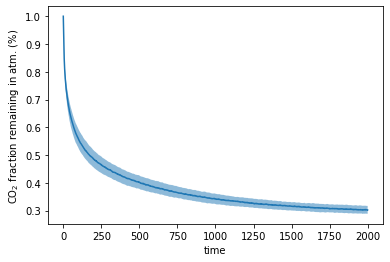

In [13]:
# Tracer les outputs du modele BERN background 500pm 
plt.plot(df_co2["yr_after_pulse"], df_co2["bg_500_50"])
plt.fill_between(df_co2["yr_after_pulse"], df_co2["bg_500_16"], df_co2["bg_500_84"], alpha=0.5)

plt.xlabel("time")
plt.ylabel(r"CO$_2$ fraction remaining in atm. (%)")

<font color="blue">

not linear, CO$_2$ still remaining after 2000. The confidence interval is relatively small (all members have same evolution)

</font>

#### Question 1.2

* _From this ensemble of simulations, how much CO$_2$ stays in the atmosphere after 10 years, 100 years, 1000 years ?_
* _How can we qualify the temporal evolution given by this model ? Does this model behave linearly in function of time ?_

In [24]:
print("After 10 years:   {:.1f}-{:.1f}%".format(100*df_co2['bg_500_16'][10], 100*df_co2['bg_500_84'][10]))
print("After 100 years:  {:.1f}-{:.1f}%".format(100*df_co2['bg_500_16'][100], 100*df_co2['bg_500_84'][100]))
print("After 1000 years: {:.1f}-{:.1f}%".format(100*df_co2['bg_500_16'][1000], 100*df_co2['bg_500_84'][1000]))

After 10 years:   77.8-82.0%
After 100 years:  52.4-59.3%
After 1000 years: 32.3-36.1%


<font color="blue">

* About 80\% of the CO$_2$ emmitted remains in the atmosphere after 10 years, ~55\% after 100 years and ~35\% after 1000 years.

  CO$_2$ is, unlike most other agents, not destroyed by chemical reactions in the atmosphere or deposited on the earth surface, but redistributed within the major carbon reservoirs: atmosphere, ocean, land biosphere. This involves multiple timescales for exchange among and for overturning within these reservoirs. A substantial fraction of the initial perturbation by the emission pulse therefore remains in the atmosphere and the ocean for millennia.

    
* The temporal evolution given by this simple box-model is not linear but instead follows an exponential decay. Rapid decrease in the first few years after the emission pulse and then a continued but slow decline.
</font>

#### Question 1.3

We are now considering the influence of the atmospheric CO$_2$ background level.

* _Plot the median and confidence intervals for the emitted CO$_2$ time-series simulated by the Bern3D model ensemble for CO$_2$ background levels of 425, 450 and 500 ppm._
* _How do you interpret the differences in the responses ?_

Text(0, 0.5, 'CO$_2$ fraction remaining in atm. (%)')

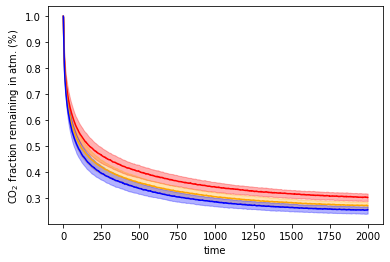

In [14]:
# Tracer les outputs du modele BERN background 500pm 
plt.plot(df_co2["yr_after_pulse"], df_co2["bg_500_50"], color="red")
plt.fill_between(df_co2["yr_after_pulse"], df_co2["bg_500_16"], df_co2["bg_500_84"], alpha=0.3, color="red")

plt.plot(df_co2["yr_after_pulse"], df_co2["bg_450_50"], color="orange")
plt.fill_between(df_co2["yr_after_pulse"], df_co2["bg_450_16"], df_co2["bg_450_84"], alpha=0.3, color="orange")

plt.plot(df_co2["yr_after_pulse"], df_co2["bg_425_50"], color="blue")
plt.fill_between(df_co2["yr_after_pulse"], df_co2["bg_425_16"], df_co2["bg_425_84"], alpha=0.3, color="blue")

plt.xlabel("time")
plt.ylabel(r"CO$_2$ fraction remaining in atm. (%)")

<font color="blue">

more the background is high and more the fraction of CO$_2$ remaining in the atmosphere is high (changes are almost linear)
    
A possible explanation for this is that all experiments used 100 GtC emission pulse which represents a different amount in proportion of the background; here it could be nice to let student convert GtC in ppm; with a factor 2.12 we have ~10%, 11% and 12% for the backgound level of 500ppm, 450pmm and 425ppm, respectively..
</font>

#### Question 1.4 

* _According to your knowledge, what are the processes able to remove CO$_2$ from the atmosphere ?_
* _Plot the atmospheric sinks of CO$_2$ $S_\text{land}$ and $S_\text{ocean}$ from the simulation outputs. Did you expect these results ?_

Text(0.5, 1.0, 'b. land')

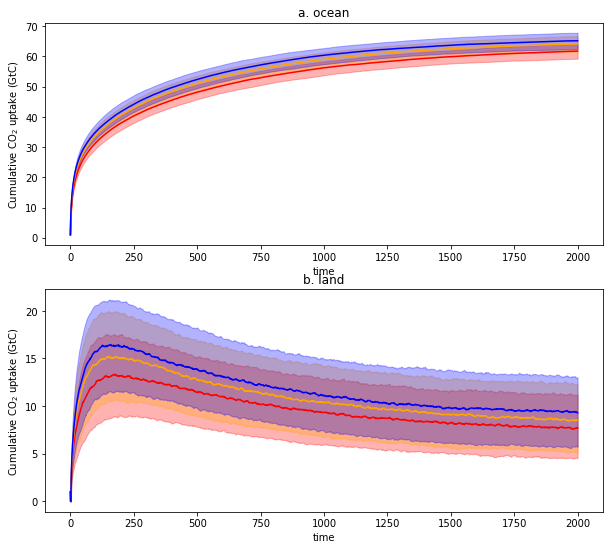

In [15]:
fig, axes = plt.subplots(2,1, figsize=(10, 9))

# Ocean
axes[0].plot(df_ocean["yr_after_pulse"], df_ocean["bg_500_50"], color="red")
axes[0].fill_between(df_ocean["yr_after_pulse"], df_ocean["bg_500_16"], df_ocean["bg_500_84"], alpha=0.3, color="red")

axes[0].plot(df_ocean["yr_after_pulse"], df_ocean["bg_450_50"], color="orange")
axes[0].fill_between(df_ocean["yr_after_pulse"], df_ocean["bg_450_16"], df_ocean["bg_450_84"], alpha=0.3, color="orange")

axes[0].plot(df_ocean["yr_after_pulse"], df_ocean["bg_425_50"], color="blue")
axes[0].fill_between(df_ocean["yr_after_pulse"], df_ocean["bg_425_16"], df_ocean["bg_425_84"], alpha=0.3, color="blue")

axes[0].set_xlabel("time")
axes[0].set_ylabel(r"Cumulative CO$_2$ uptake (GtC)")
axes[0].set_title("a. ocean")
# Land
axes[1].plot(df_land["yr_after_pulse"], df_land["bg_500_50"], color="red")
axes[1].fill_between(df_land["yr_after_pulse"], df_land["bg_500_16"], df_land["bg_500_84"], alpha=0.3, color="red")

axes[1].plot(df_land["yr_after_pulse"], df_land["bg_450_50"], color="orange")
axes[1].fill_between(df_land["yr_after_pulse"], df_land["bg_450_16"], df_land["bg_450_84"], alpha=0.3, color="orange")

axes[1].plot(df_land["yr_after_pulse"], df_land["bg_425_50"], color="blue")
axes[1].fill_between(df_land["yr_after_pulse"], df_land["bg_425_16"], df_land["bg_425_84"], alpha=0.3, color="blue")

axes[1].set_xlabel("time")
axes[1].set_ylabel(r"Cumulative CO$_2$ uptake (GtC)")
axes[1].set_title("b. land")

<font color="blue">

Pression partielle a la surface de l'océan en premier lieu 
    
Et pour la biosphere c la photosynthèse
    
Interessant de noter que sur le long-term l'océan et la biosphere réagisse différement:
    
- the response in ocean carbon inventory to an emission pulse is relatively well understood. Ocean uptake is mainly
driven by physico-chemical processes and uptake rates are governed by the quantitatively well-understood carbonate
chemistry in surface waters and by the rates of surface-to-deep transport. The latter are constrained by the distribution of transient tracers such as CFCs and bomb-produced radio-carbon in the thermocline (Key et al., 2004). In early generation carbon cycle models such as the Bern-SAR model only these physico-chemical processes were included. This first-order response is modified by other processes such as ocean warming and changes in ocean circulation and marine biogeochemistry.
    
    
- the response of the land biosphere carbon inventory is associated with considerable uncertainties. It is currently not clear whether the land will continue to act as a strong carbon sink or whether climate change will lead to a loss of land carbon that overwhelms the potentially positive influence of elevated atmospheric CO 2 and nitrogen input on net primary productivity and carbon stocks. This limited understanding is reflected in the large uncertainty range. We estimate the 5 to 95 % confidence range for the response in land carbon inventory to 45 GtC at year 100. For comparison, the corresponding uncertainty range for the ocean inventory is 29 GtC.
    
In conclusion, carbon uptake by the land biosphere is about equally important for the evolution of IRF$_{CO_2}$ as up-take by the ocean during the first two decades after the release.

</font>

<a id="section-2"></a>
## 2. Analytical representation of the response

In this section, we will simplify the climate response to an emission pulse of CO$_2$ and use a simple box model to track the evolution of the atmospheric CO$_2$. 

In mathematical terms, the box model can be written as:

$$
\frac{d \text{CO}_2(t)}{dt} = E(t) - \frac{\text{CO}_2(t)}{\tau_{\text{CO}_2}}
$$
where $E$ represent the emissions and all sinks are defined using a first-order decay hypothesis with a characteristic decay time $\tau_{\text{CO}_2}$.

The analytical solution of this equation for an emission pulse ($E(t) = \delta(0)$ with $\delta$ is the Dirac delta function) is called an Impulsional Response Function (IRF).


#### Question 2.1

* _What are the analytical solution the IRF of CO$_2$ ? Does it fit your previous figures (Question 1.1) ?_
* _Fit parameters of your analytical solution to match the median of the Bern3D ensemble-members for the first 10 years of the simulations._
* _What do you think about your fit ? Does taking the first 100 years, 1000 years, 2000 years improve the results ?_

__Help:__ you can use the function [scipy.fmin](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.fmin.html) to iterate through a set of parameters and to minimize the error.

In [36]:
# fit dynamical parameters

# initialization
a_0 = 0
a_1 = 0
tau_1 = 0

time = df_co2["yr_after_pulse"]
def err_1exp(var):
    fit = var[0] + (1-var[0])*np.exp(-time/var[1])
    return sum(( fit[:500] - (df_co2["bg_500_50"][0:500]))**2)  # SSE (Sum of Squared Errors)
[a_0, tau_1] = fmin(err_1exp,[0, 100],disp=False)

a_1 = 1 - a_0
[a_0, a_1, tau_1]

[0.44307364958520234, 0.5569263504147977, 52.86099052988627]

Text(0, 0.5, 'Error')

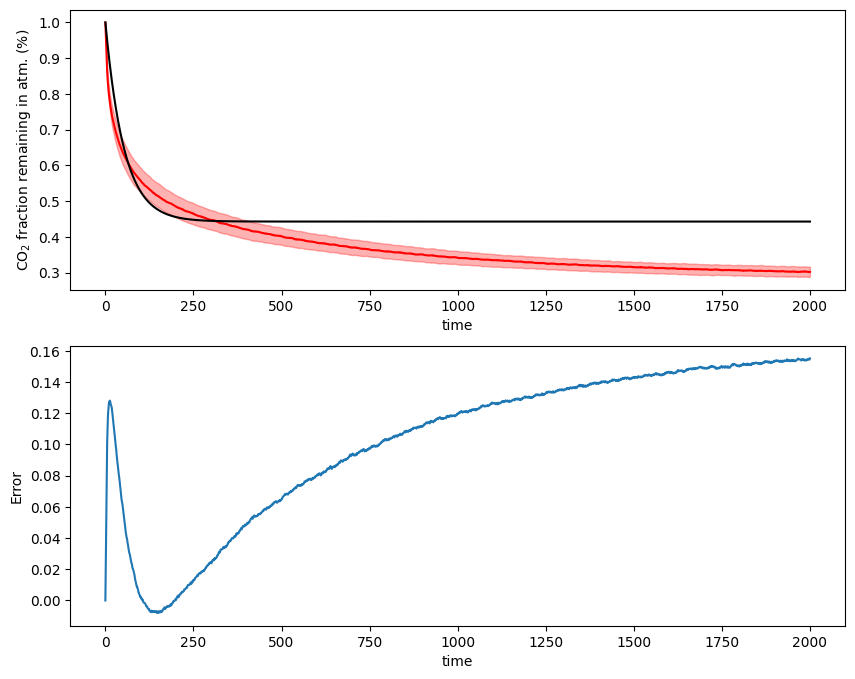

In [37]:
# Tracer les outputs du modele BERN background 500pm 
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
axes[0].plot(df_co2["yr_after_pulse"], df_co2["bg_500_50"], color="red")
axes[0].fill_between(df_co2["yr_after_pulse"], df_co2["bg_500_16"], df_co2["bg_500_84"], alpha=0.3, color="red")


axes[0].set_xlabel("time")
axes[0].set_ylabel(r"CO$_2$ fraction remaining in atm. (%)")

# Fit
year = np.arange(0,2001,1)
axes[0].plot(year, a_0 + a_1*np.exp(-year/tau_1), color="k")


# Error in fit

axes[1].plot(year, a_0 + a_1*np.exp(-year/tau_1) - df_co2["bg_500_16"])
axes[1].set_xlabel("time")
axes[1].set_ylabel(r"Error")


<font color="blue">

Pas ouf, une exponentielle n'est pas suffisante
    
</font>

#### Question 2.2 

We will now try to improve the fit.

* _Improve the analytical fit by adding a second box model similar to the one in Question 2.1_.
* _Compute the errors with the simulated data. How much improvements have been made ?_

In [38]:
# fit dynamical parameters

# initialization
a_0 = 0
a_1 = 0
tau_1 = 0
a_2 = 0
tau_2 = 0

time = df_co2["yr_after_pulse"]
def err_2exp(var):
    fit = var[0] + var[1]*np.exp(-time/var[2]) + (1-var[1]-var[0])*np.exp(-time/var[3])
    return sum(( fit - (df_co2["bg_500_50"]))**2) # SSE (Sum of Squared Errors)
[a_0, a_1, tau_1, tau_2] = fmin(err_2exp,[0.5, 0.5, 10, 100],disp=False)

a_2 = 1 - a_1 - a_0
[a_0, a_1, a_2, tau_1, tau_2]

[0.3045711586021992,
 0.403230218253546,
 0.2921986231442548,
 23.261734311371452,
 458.24031802825505]

Text(0, 0.5, 'Error')

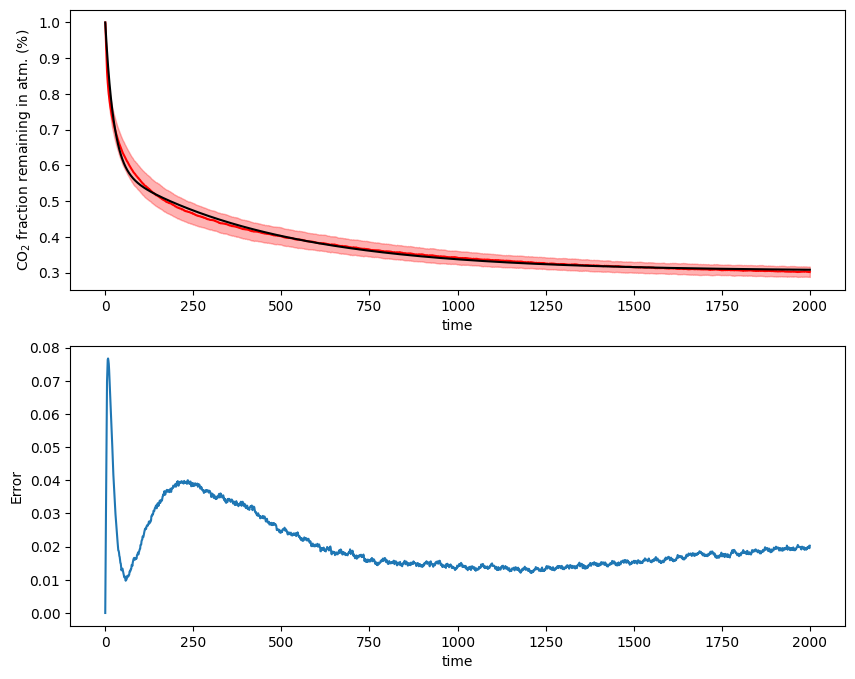

In [39]:
# Tracer les outputs du modele BERN background 500pm 
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
axes[0].plot(df_co2["yr_after_pulse"], df_co2["bg_500_50"], color="red")
axes[0].fill_between(df_co2["yr_after_pulse"], df_co2["bg_500_16"], df_co2["bg_500_84"], alpha=0.3, color="red")


axes[0].set_xlabel("time")
axes[0].set_ylabel(r"CO$_2$ fraction remaining in atm. (%)")

# Fit
year = np.arange(0,2001,1)
axes[0].plot(year, a_0 + a_1*np.exp(-year/tau_1) + a_2*np.exp(-year/tau_2), color="k")

# Error in fit

axes[1].plot(year, a_0 + a_1*np.exp(-year/tau_1) + a_2*np.exp(-year/tau_2) - df_co2["bg_500_16"])
axes[1].set_xlabel("time")
axes[1].set_ylabel(r"Error")


<font color="blue">

Pas mal, mais on peut faire encore mieux
    
</font>

#### Question 2.3

* _Find the minimal number of box models to include that satisfy our fit. Explain your choice._

In [40]:
# fit dynamical parameters

# initialization
a_0 = 0
a_1 = 0
tau_1 = 0
a_2 = 0
tau_2 = 0
a_3 = 0
tau_3 = 0

time = df_co2["yr_after_pulse"]
def err_3exp(var):
    fit = var[0] + var[1]*np.exp(-time/var[2]) + var[3]*np.exp(-time/var[4]) + (1-var[3]-var[1]-var[0])*np.exp(-time/var[5])
    return sum(( fit - (df_co2["bg_500_50"]))**2) # SSE (Sum of Squared Errors)
[a_0, a_1, tau_1, a_2, tau_2, tau_3] = fmin(err_3exp,[0.2, 0.2, 400, 0.2, 30, 3],disp=False)

a_3 = 1 - a_2 - a_1 - a_0
[a_0, a_1, a_2, a_3, tau_1, tau_2,  tau_3]

[0.2950196151560378,
 0.24700356259214584,
 0.24759548229442283,
 0.2103813399573935,
 597.9204731929267,
 65.73691968468935,
 6.921696890562096]

Text(0, 0.5, 'Error')

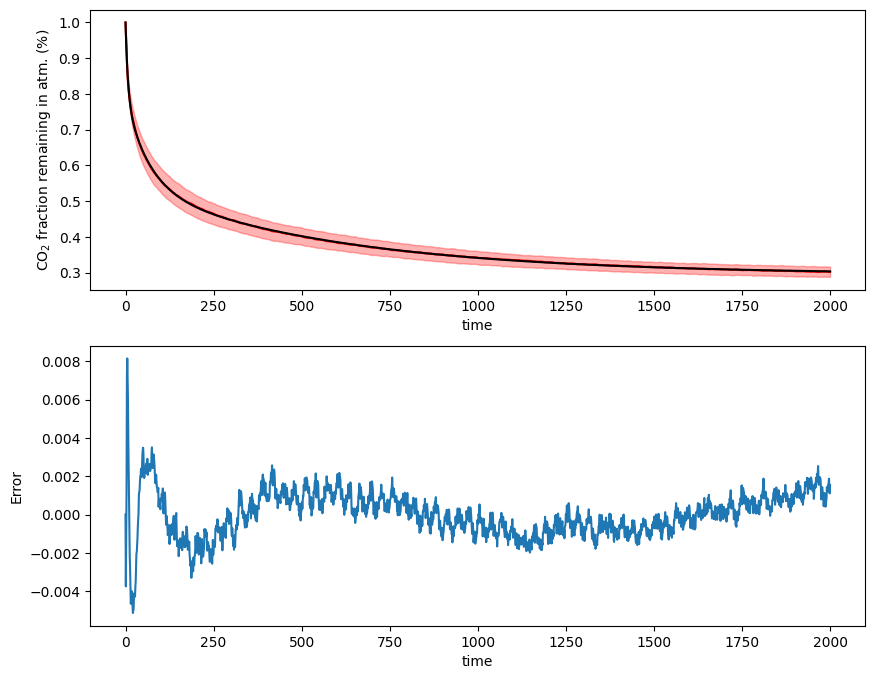

In [48]:
# Tracer les outputs du modele BERN background 500pm 
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
axes[0].plot(df_co2["yr_after_pulse"], df_co2["bg_500_50"], color="red")
axes[0].fill_between(df_co2["yr_after_pulse"], df_co2["bg_500_16"], df_co2["bg_500_84"], alpha=0.3, color="red")


axes[0].set_xlabel("time")
axes[0].set_ylabel(r"CO$_2$ fraction remaining in atm. (%)")

# Fit
year = np.arange(0,2001,1)
intermediaire = a_0 + a_1*np.exp(-time/tau_1) + a_2*np.exp(-time/tau_2) + a_3*np.exp(-time/tau_3)
axes[0].plot(year, intermediaire, color="k")

# Error in fit
axes[1].plot(year, intermediaire - df_co2["bg_500_50"])
axes[1].set_xlabel("time")
axes[1].set_ylabel(r"Error")


<font color="blue">

3 comme dans le papier référence ! Faire comprendre aux élèves que moins de paramètres = mieux si résultat suffisant

</font>

#### Question 2.4

* _According your knowledge, to what correspond the different box models of the IRF ?_
* _What do they represent ? How do they evolve individually ?_

__Help__ : What are the units of $\tau_{C,}$ and $a_{C,}$ ?


<font color="blue">

* The IRF equation is modelled as a sum of three exponential decay. This can be interpreted as a sum of four distinct box-models somewhat representing processes associated to Earth system components (atmosphere, ocean and biosphere).
  
<div align="center"><img src="../figures/Four-box-models.png" alt="drawing" width="600"/></div>

* $a_{C,i}$ are unitless coefficients which represent a fraction that is associated with a certain nominal timescale $\tau_{C,i}$ (units in year). The three different timescales are therefore related to the time response of the three box-models (or natural CO$_2$ removal processes). It is important to note the difference in the values meaning that the process act on very different timescales: around 4, 40 and 400 years (surface adjustement, biosphere, primary production, calcification and slower deep ocean penetration). However, the interpretation for the values of $a_{C,i}$ is not straightforward, but we can notice they are all similar ~0.25 (meaning that the CO$_2$ at the equilibrium is well reparted between the four box-model (E).  
  
However, in [Joos et al. (2013)](https://acp.copernicus.org/articles/13/2793/2013/acp-13-2793-2013.html), the authors clearly note that _"the coefficients $a_{C,i}$ and $\tau_{C,i}$ have no direct process-based meaning, but are fitting parameters chosen to represent a given model-based IRF$_{CO2}$ "_.

Indeed the removal of carbon dioxide from the atmosphere is complex and involves several dynamical processes [(Solomon et al., 2009)](https://www.pnas.org/doi/10.1073/pnas.0812721106), and timescales from weeks to millennia:

* _"rapid exchange with the land biosphere and the surface layer of the ocean through air–sea exchange"_

   - in the ocean, dissolved carbon can be pumped from biological processes (primary production sedimentation or via the formation of CaCO3 used by mollusc shells and limestones).
   - exchanges with the terrestrial biosphere are linked to the functioning of ecosystems (and therefore to their seasonality): CO2 is absorbed by plants through photosynthesis, then released back into the atmosphere through respiration.
<p></p>

* _"much slower penetration to the ocean interior that is dependent upon the buffering effect of ocean chemistry along with vertical transport_".
* *"On the time scale of a millennium, the CO$_2$ equilibrates largely between the atmosphere and the ocean and, depending on associated increases in acidity and in ocean warming, typically ~20% of the added tonnes of CO$_2$ remain in the atmosphere while ~80% are mixed into the ocean."*
     
</font>

#### Question 2.5

* _What is the mathemathical relationship between the sink of CO$_2$ and the IRF for atmopsheric CO$_2$ ?_
* _Determine the formulation of this flux of CO$_2$ and produce a figure._ 
* _How do you interpret the sign of this flux and its final value ?_
* _Could you retreive this flux from the Bern3D simulation outputs ?_



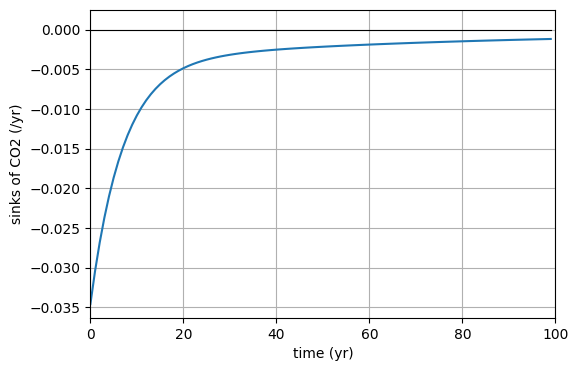

In [52]:
# definition of the carbon sink function
def sinks_CO2(t):
    irf =  -a_1/tau_1 * np.exp(-t/tau_1) - a_2/tau_2 * np.exp(-t/tau_2) - a_3/tau_3 * np.exp(-t/tau_3)
    return irf

# plot the C sinks response to a pulse of emissions
plt.figure(figsize=(6,4))
t = np.arange(100)
plt.plot(t, np.zeros_like(t), c='k', lw=0.8)
plt.plot(t, sinks_CO2(t))
plt.xlim(0, 100)
plt.ylim(None, 0.0025)
plt.ylabel('sinks of CO2 (/yr)')
plt.xlabel('time (yr)')
plt.grid(True)

(0.0, 100.0)

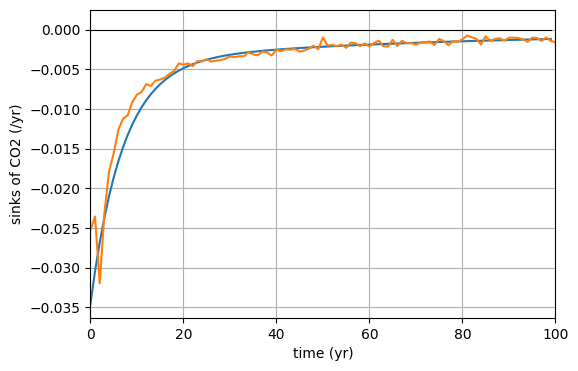

In [60]:
# plot the C sinks response to a pulse of emissions
plt.figure(figsize=(6,4))
t = np.arange(100)
plt.plot(t, np.zeros_like(t), c='k', lw=0.8)
plt.plot(t, sinks_CO2(t))
plt.xlim(0, 100)
plt.ylim(None, 0.0025)
plt.ylabel('sinks of CO2 (/yr)')
plt.xlabel('time (yr)')
plt.grid(True)

# plot Bern3D sinks
S_land  = (df_land['bg_500_50'][1:].to_numpy() - df_land['bg_500_50'][:-1].to_numpy()) / 100
S_ocean = (df_ocean['bg_500_50'][1:].to_numpy() - df_ocean['bg_500_50'][:-1].to_numpy()) / 100

plt.plot(np.arange(2000), -(S_land + S_ocean))
plt.xlim(0, 100)

<font color="blue">

* The IRF represents the CO$_2$ and is solution to the first-order decay equation. It is unitless and shows how the CO$_2$ is removed from the atmosphere by sinks.

* Sinks of CO$_2$ $(S)$ for each year is given by the derivative of the IRF:
$$
S = \frac{\partial \text{IRF}_{\text{CO}_2}(t)}{\partial t} = -\frac{a_{C,1}}{\tau_{C,1}}\exp\left({\frac{-t}{\tau_{C,1}}}\right)
                                                              -\frac{a_{C,2}}{\tau_{C,2}}\exp\left({\frac{-t}{\tau_{C,2}}}\right)
                                                              -\frac{a_{C,3}}{\tau_{C,3}}\exp\left({\frac{-t}{\tau_{C,3}}}\right)
$$

* negative flux means CO$_2$ is removed from the atmosphere and transferred to another climate component (ocean and lands). A horizontal assymptote is observed and $S\rightarrow 0$ for $t\rightarrow\infty$ meaning the sinks do not act or the system reach an equilibrium state. However as discussed before, on multimillenium and longer time scales, geochemical and geological processes could restore atmospheric carbon dioxide to its pre industrial values [(Montenegro et al., 2007)](https://agupubs.onlinelibrary.wiley.com/doi/10.1029/2007GL030905), but are not considered here.

</font>

<a id="section-3"></a>
## 3. Simulating the historical evolution of CO$_2$ concentration

Anthropogenic CO$_2$ emissions are relatively well known since they are estimated from human/commercial/energetical activities. They are collected by various institute and countries since decades. This emissions data are available on the [Carbon Dioxide Information Analysis Center (CDIAC)](https://rieee.appstate.edu/projects-programs/cdiac/). 

Here, we will use our IRF associated with emission data to simulate the atmopsheric CO$_2$ increase.

The code below loads emissions data from CDIAC inventories as well as greenhouse gases concentration:

In [69]:
obs_dir = '../data/OBSERVATIONS/'


# CO2 emissions
CO2_eff = np.array([line for line in \
    csv.reader(open("../data/CDIAC_EFF.global.1751_2011.csv","r"))][2:],dtype=float)[:,2:-1]
CO2_lbl = [line for line in \
    csv.reader(open("../data/CDIAC_EFF.global.1751_2011.csv","r"))][0][2:-1]

CDIAC = {'global': xr.Dataset()}
for i, em in enumerate(CO2_lbl):
    v  = em.lower().replace(' ', '_')
    da = xr.DataArray(data=CO2_eff[:,i], dims=('year'), coords={'year': np.arange(1750,2011)})
    da = da / 1000 / 2.13   #{ppm/yr}
    da.name = v
    
    CDIAC['global'][v] = da
    
da = xr.DataArray(data=np.sum(CO2_eff,1), dims=('year'), coords={'year': np.arange(1750,2011)})
da = da / 1000 / 2.13   #{ppm/yr}
da.name = 'total_carbon_emissions'
    
CDIAC['global']['total_carbon_emissions'] = da


# Greenhouse gases atmospheric concentration
GHGConc = {
    'global': xr.load_dataset(
        obs_dir+'input4MIPs_GHGConcentrations_CMIP_UoM-CMIP-1-2-0_gr1-GMNHSH_0001-2014.nc', use_cftime=True
    ),
}


#### Question 3.1

* _Plot a figure showing the temporal evolution of the different type of fossil CO2 emissions._


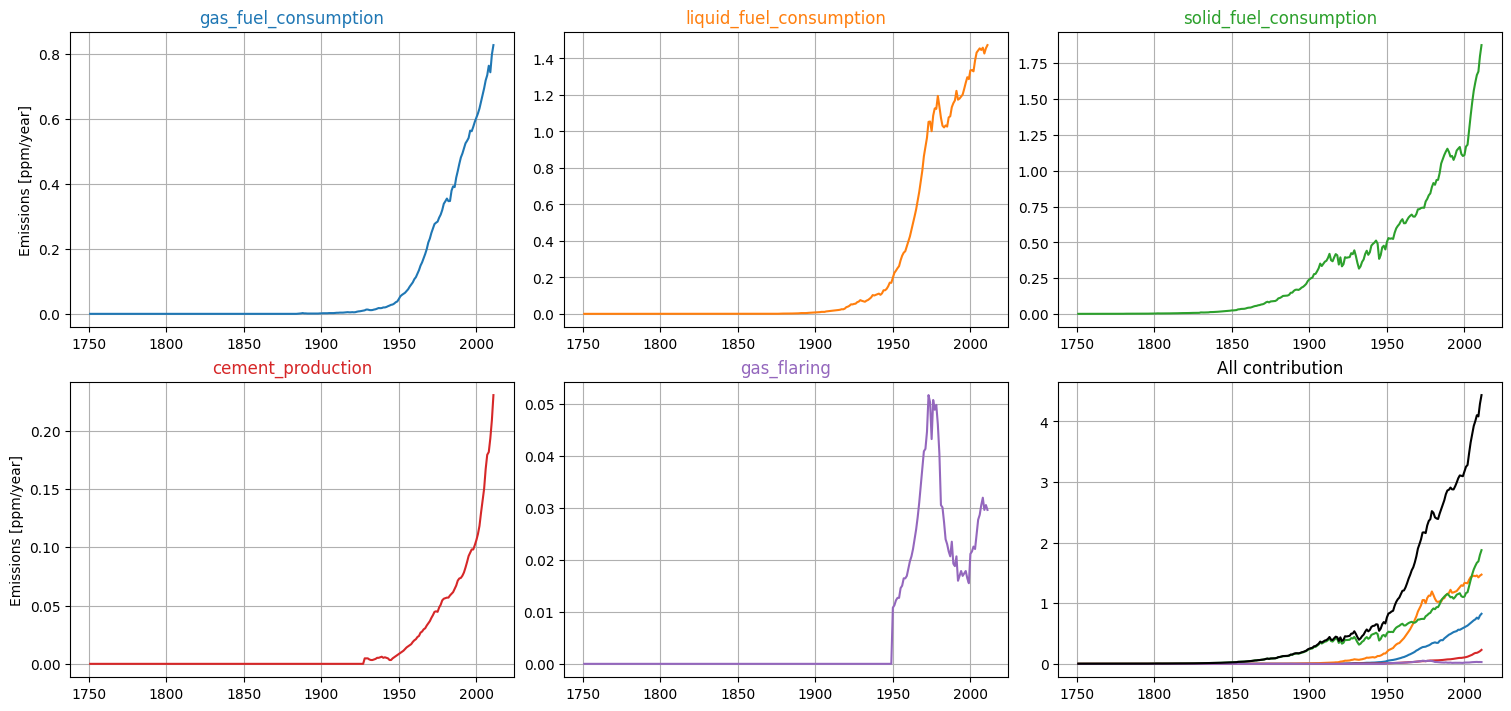

In [64]:
fig, axs = plt.subplots(2, 3, layout='constrained', figsize=(15, 7))
gridspec = axs[0, 0].get_subplotspec().get_gridspec()

colors   = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple'] 

for i in range(len(CDIAC['global'].variables)-2):
    lgd = list(CDIAC['global'].variables)[i+1]
    dat = CDIAC['global'][lgd]
    col = colors[i]
    
    ax  = axs[i//3, i%3] 

    ax.set_title(lgd.split('carbon_emissions_from_')[1], y=1, color=col)
    ax.plot(np.arange(1751, 1751+len(dat)), dat, color=col)

    axs[1,2].plot(np.arange(1751, 1751+len(dat)), dat, color=col, label=lgd)

    ax.grid(True)

    if i%3 == 0:
        ax.set_ylabel("Emissions [ppm/year]")

# all contrib
dat = CDIAC['global']['total_carbon_emissions']
axs[1,2].set_title('All contribution')
axs[1,2].plot(np.arange(1751, 1751+len(dat)), dat, color='k', label='total')

axs[1,2].grid(True)

<font color="blue">

CO$_2$ emissions are exponentially growing and started at different periods. The earliest emissions come from solid fuel and started during the 19th century (industrial revolution). Other emessions are more recent (e.g. cement production and gas flaring). 
    
Before, 1850 almost no CO$_2$ have been emitted due to human activity. It is therefore a natural choice to started simulation of climate change.
    
</font>

#### Question 3.2

Assuming a linear response of the CO$_2$ concentration, its changes can be computed from the convolution between CO$_2$ **emissions** and the IRF for CO$_2$:

$$ \Delta \text{CO}_2(t_n) = \sum_{i=0}^n E_X(t_i)\,\text{IRF}_{\text{CO}_2}(t_{n-i})\,\Delta t 
   \quad\quad \text{pour }\Delta t \rightarrow 0: \quad
   \Delta \text{CO}_2(t) = \int_0^t E_X(t')\,\text{IRF}_{\text{CO}_2}(t-t')\,dt'$$ 

More on convolution on [Wikipedia](https://en.wikipedia.org/wiki/Convolution) or in this [tutorial](../tools/Convolution.ipynb).

* _Use a convolution to estimate the CO$_2$ concentration through the emission and the IRF._
* _Compare your estimation with the one derived from observation._
* _Add confidence intervals on your results ?_


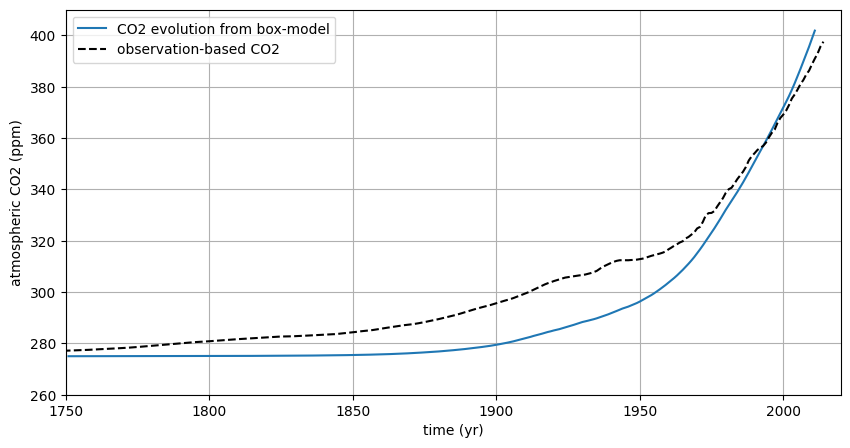

In [86]:
Etot = CDIAC['global']['total_carbon_emissions']
conv = np.zeros(np.shape(Etot))

# definition of the IRF for atmospheric CO2
def irf_CO2(t):
    irf = a_0 + a_1 * np.exp(-t/tau_1) + \
                a_2 * np.exp(-t/tau_2) + \
                a_3 * np.exp(-t/tau_3)
    return irf

for t in range(len(Etot)):
    conv[t] = np.sum(Etot[:t+1] * irf_CO2(np.arange(t+1))[::-1]) # [::-1] to turn around the order


# compare the three simulated atmospheric CO2 and the reconstruction
plt.figure(figsize=(10, 5))
plt.plot(np.arange(1751,1751+len(Etot)), conv+275, label='CO2 evolution from box-model')

# plot different greenhouse gas concentrations
v      = 'mole_fraction_of_carbon_dioxide_in_air'

# read units in array attributes
units  = float(GHGConc['global'][v].attrs['units']) * 1e6  # 1e-6 keep units in ppm

# get data and convert into eq. CO2: C = C[0] + dC * ERF
conc   = GHGConc['global'][v].groupby('time.year').sum()   # sum or mean (since data are yearly already)
conc   = conc[1750] + (conc - conc[1750])

# add on figure
plt.plot(conc['year'], units*conc, ls='--', color='k', label='observation-based CO2')

#
plt.xlim((1750, 2020))
plt.ylim((260, 410))

plt.ylabel('atmospheric CO2 (ppm)')
plt.xlabel('time (yr)')
plt.grid(True)
plt.legend(loc=0)

<font color="blue">

Our model underestimate the CO$_2$ concentration at least since ~1980 
    
</font>

#### Question 3.3

* _Would you obtain different results and conclusion by fitting your IRF with another CO$_2$ background levels ?_
* _What do you think about the convolution for estimating the CO$_2$ concentration ?_ 


In [ ]:
# Redo the work with the other

<font color="blue">

We should get less CO$_2$ concentration by decreasing level background; this raise question about the linear response of the CO$_2$ e
    
</font>